In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [ ]:
train = pd.read_csv("../data/train_test.csv", parse_dates=["date"])
valid = pd.read_csv("../data/validation.csv", parse_dates=["date"])
december = pd.read_csv("../data/december-chart-inputs.csv", parse_dates=["date"])

#  use rate per mile instead of raw rates
train["rpm"] = train["posted_rate"] / train["distance"]
train["month"] = train["date"].dt.to_period("M")

In [11]:
#  Overview
for name, df in [("train", train), ("validation", valid)]:
    print(f"===== {name}: {df.shape} =====")
    print("Date range:", df["date"].min().date(), "->", df["date"].max().date())
    print("Duplicate load_id:", df["load_id"].duplicated().sum())
    print("Duplicate rows (ignoring load_id):", df.drop(columns="load_id").duplicated().sum())
    print("Missing values:\n", df.isna().sum()[lambda s: s > 0].to_string())
    print(df.describe().T[["mean", "min", "50%", "max"]].round(2),end='\n')

print("\nEquipment mix (share):")
print(pd.concat({"train": train["equipment"].value_counts(normalize=True),
                 "valid": valid["equipment"].value_counts(normalize=True)}, axis=1).round(3))


===== train: (48000, 16) =====
Date range: 2025-01-01 -> 2025-10-31
Duplicate load_id: 0
Duplicate rows (ignoring load_id): 0
Missing values:
 weight          300
market_index    374
                                    mean                  min  \
pickup_lat                     35.647545             28.35765   
pickup_lon                    -90.928964           -121.69849   
delivery_lat                   35.641175             28.35765   
delivery_lon                   -90.85731           -121.69849   
distance                     1135.856654                 70.0   
weight                      31028.844004             -47500.0   
date          2025-05-31 19:53:29.400000  2025-01-01 00:00:00   
market_index                    1.083387              0.67639   
quote_signal                    2.062468              0.69228   
posted_rate                  2373.980682                57.22   
rpm                             2.215347             0.333709   

                              50%   

In [12]:
#  checking data quality 
# 1. Weight (negatives, missing, and cap)
for name, df in [("train", train), ("valid", valid)]:
    w = df["weight"]
    print(f"{name}: negative weight={int((w < 0).sum())}, "
          f"weight==47500 (cap)={int((w == 47500).sum())}, missing={int(w.isna().sum())}")

# 2. Outliers, measured as rate per mile
q = train["rpm"].quantile([0, .001, .005, .01, .5, .99, .995, .999, 1])
print("\nRate-per-mile quantiles:\n", q.round(2).to_string())

low, high = 1.0, 5.0
bad = train[(train["rpm"] < low) | (train["rpm"] > high)]
print(f"Rows with rpm outside [{low}, {high}]: {len(bad)} ({len(bad) / len(train):.2%})")
print(bad.sort_values("rpm")[["pickup", "delivery", "distance", "equipment", "posted_rate", "rpm"]]
      .iloc[[0, 1, 2, -3, -2, -1]].round(2))

# 3. Map each city to only one coordinate pair
cities = pd.concat([
    df[[side, f"{side}_lat", f"{side}_lon"]].set_axis(["city", "lat", "lon"], axis=1)
    for df in (train, valid) for side in ("pickup", "delivery")
]).drop_duplicates()
print("\nCities with more than one coordinate pair:", cities["city"].duplicated().sum())
print("Cities on the coordinate clip edge (lat=25.5 or lon=-69.5):")
print(cities[(cities["lat"] == 25.5) | (cities["lon"] == -69.5)].to_string(index=False))


train: negative weight=292, weight==47500 (cap)=1191, missing=300
valid: negative weight=145, weight==47500 (cap)=297, missing=165

Rate-per-mile quantiles:
 0.000     0.33
0.001     0.44
0.005     0.75
0.010     1.67
0.500     2.15
0.990     3.18
0.995     6.31
0.999    10.07
1.000    14.13
Rows with rpm outside [1.0, 5.0]: 646 (1.35%)
            pickup      delivery  distance equipment  posted_rate    rpm
14102      Buffalo   Bakersfield    2536.4   Dry Van       846.42   0.33
25798       Albany          Reno    2894.3   Dry Van       969.83   0.34
23043      Phoenix  Philadelphia    2983.4   Dry Van      1047.91   0.35
870          Tulsa   Baton Rouge     305.6    Reefer      4069.24  13.32
36609  Chattanooga       Atlanta      98.4    Reefer      1386.42  14.09
22254   Greensboro    Cincinnati     314.7    Reefer      4445.23  14.13

Cities with more than one coordinate pair: 0
Cities on the coordinate clip edge (lat=25.5 or lon=-69.5):
      city      lat       lon
Providence 37.

In [13]:
def haversine_miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

train["haversine"] = haversine_miles(train["pickup_lat"], train["pickup_lon"],
                                     train["delivery_lat"], train["delivery_lon"])
ratio = train["distance"] / train["haversine"]
print("Road / straight-line distance quantiles:\n", ratio.quantile([.01, .5, .99]).round(2).to_string())

train_cities = set(train["pickup"]) | set(train["delivery"])
valid_cities = set(valid["pickup"]) | set(valid["delivery"])
unseen = sorted(valid_cities - train_cities)
unseen_rows = valid["pickup"].isin(unseen) | valid["delivery"].isin(unseen)
print(f"\nUnseen cities in validation ({len(unseen)}): {unseen}")
print(f"Validation loads touching an unseen city: {unseen_rows.sum():,} ({unseen_rows.mean():.1%})")


Road / straight-line distance quantiles:
 0.01    1.13
0.50    1.18
0.99    1.40

Unseen cities in validation (8): ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
Validation loads touching an unseen city: 1,447 (12.1%)


In [14]:
num_cols = ["distance", "weight", "market_index", "quote_signal"]
print("Correlation with posted_rate and with rate per mile:")
print(pd.DataFrame({
    "posted_rate": train[num_cols].corrwith(train["posted_rate"]),
    "rpm": train[num_cols].corrwith(train["rpm"]),
}).round(3))

print("\nMedian rate per mile by equipment:")
print(train.groupby("equipment")["rpm"].median().round(3).to_string())

print("\nMonthly trend:")
print(train.groupby("month").agg(loads=("rpm", "size"),
                                 median_rpm=("rpm", "median"),
                                 market_index=("market_index", "mean"),
                                 quote_signal=("quote_signal", "mean")).round(3))

print("\nMedian rate per mile by day of week (0=Mon):")
print(train.groupby(train["date"].dt.dayofweek)["rpm"].median().round(3).to_string())

# Short hauls carry a higher per-mile price (fixed costs spread over fewer miles)
train["dist_band"] = pd.cut(train["distance"], [0, 250, 500, 1000, 1500, 2500, 4000])
print("\nMedian rate per mile by distance band:")
print(train.groupby("dist_band", observed=True)["rpm"].median().round(3).to_string())


Correlation with posted_rate and with rate per mile:
              posted_rate    rpm
distance            0.909 -0.335
weight              0.035  0.075
market_index        0.034  0.083
quote_signal       -0.040  0.049

Median rate per mile by equipment:
equipment
Dry Van    2.046
Flatbed    2.220
Reefer     2.312

Monthly trend:
         loads  median_rpm  market_index  quote_signal
month                                                 
2025-01   4918       2.029         0.927         2.068
2025-02   4337       2.061         0.996         2.097
2025-03   5036       2.139         1.073         2.180
2025-04   4819       2.147         1.208         1.963
2025-05   4913       2.190         1.301         1.913
2025-06   4783       2.248         1.280         2.296
2025-07   4912       2.187         1.201         1.923
2025-08   4759       2.121         0.981         2.052
2025-09   4670       2.160         0.893         2.200
2025-10   4853       2.164         0.958         1.943

Median r

In [15]:
# Raw correlations are swamped by distance and outliers
clean = train[(train["rpm"] >= low) & (train["rpm"] <= high)].copy()
clean["rpm_resid"] = clean["rpm"] - clean.groupby(["equipment", "dist_band"], observed=True)["rpm"].transform("median")
print("Correlation with rpm residual:")
print(clean[["market_index", "quote_signal", "weight"]].corrwith(clean["rpm_resid"]).round(3).to_string())


Correlation with rpm residual:
market_index    0.343
quote_signal    0.047
weight          0.308


In [16]:
drift = pd.DataFrame({
    "train_mean": train[num_cols].mean(),
    "train_Sep-Oct": train.loc[train["date"] >= "2025-09-01", num_cols].mean(),
    "valid_mean": valid[num_cols].mean(),
}).round(3)
print(drift)
print("\nValidation monthly signals:")
print(valid.groupby(valid["date"].dt.to_period("M"))[["market_index", "quote_signal"]].mean().round(3))

lane = train[(train["pickup"] == "Lexington") & (train["delivery"] == "Fort Wayne")]
print(f"\nLexington -> Fort Wayne in training: {len(lane)} loads")
print(lane.groupby("equipment")["posted_rate"].describe()[["count", "mean", "min", "max"]].round(1))
print("December input columns:", list(december.columns))


              train_mean  train_Sep-Oct  valid_mean
distance        1135.857       1135.243    1141.773
weight         31028.844      31179.120   30506.636
market_index       1.083          0.926       0.927
quote_signal       2.062          2.069       2.051

Validation monthly signals:
         market_index  quote_signal
date                               
2025-11         0.919         2.055
2025-12         0.935         2.048

Lexington -> Fort Wayne in training: 32 loads
           count   mean    min    max
equipment                            
Dry Van     21.0  823.3  757.9  934.4
Flatbed      3.0  880.6  844.1  919.8
Reefer       8.0  934.9  901.4  973.8
December input columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


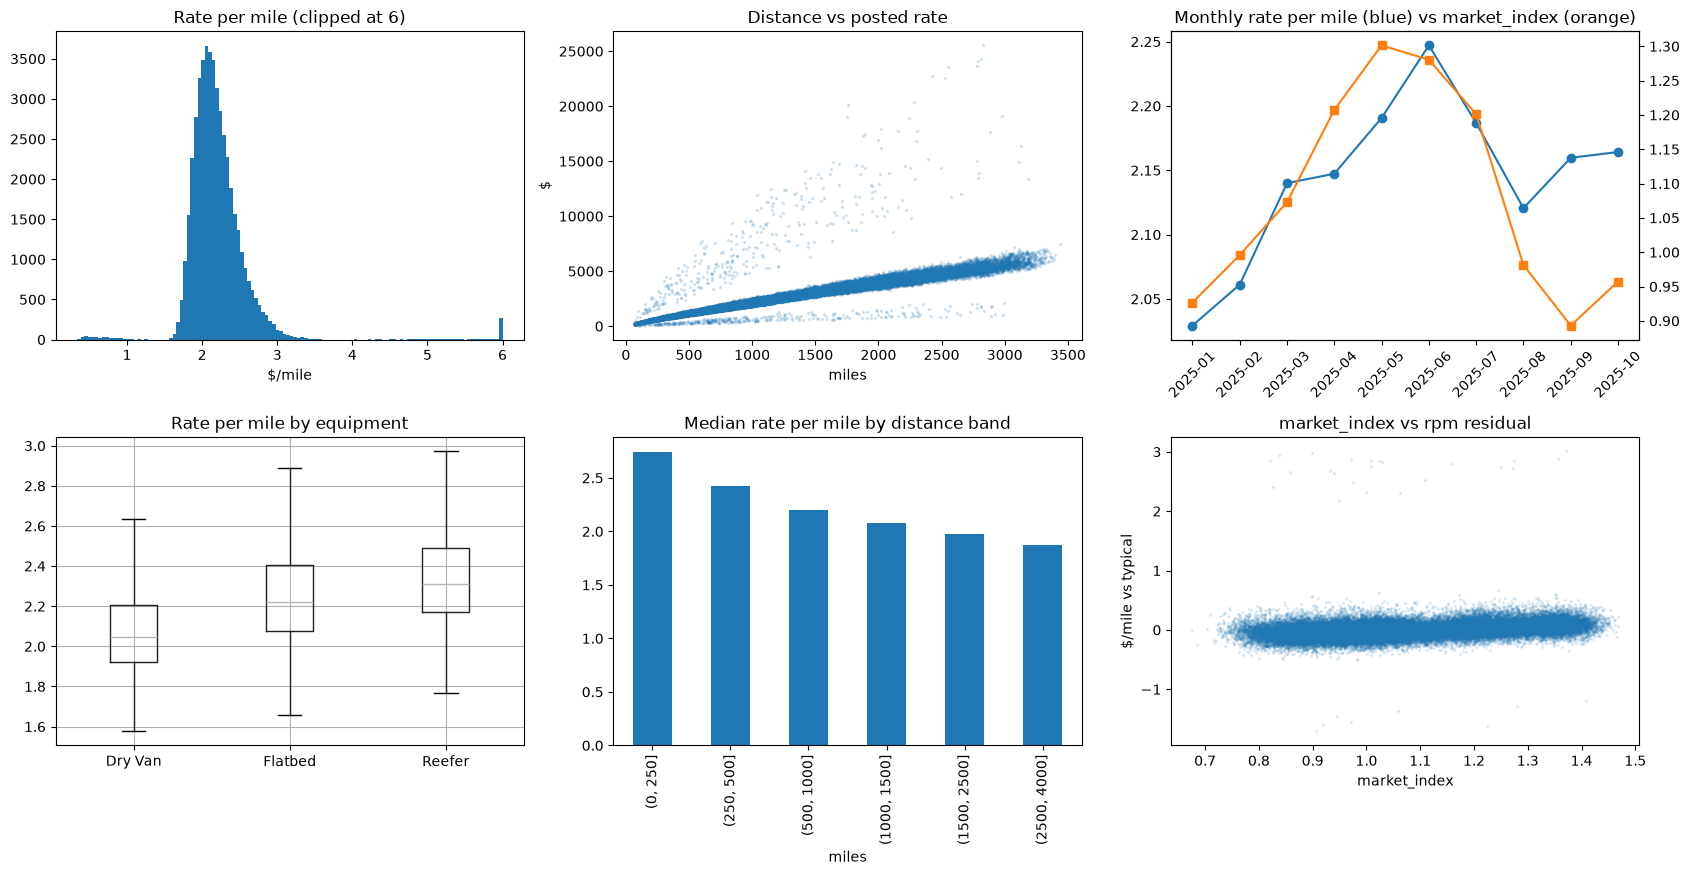

In [17]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))

ax[0, 0].hist(train["rpm"].clip(upper=6), bins=120)
ax[0, 0].set(title="Rate per mile (clipped at 6)", xlabel="$/mile")

ax[0, 1].scatter(train["distance"], train["posted_rate"], s=2, alpha=0.15)
ax[0, 1].set(title="Distance vs posted rate", xlabel="miles", ylabel="$")

monthly = clean.groupby("month").agg(rpm=("rpm", "median"), mi=("market_index", "mean"))
ax[0, 2].plot(monthly.index.astype(str), monthly["rpm"], marker="o", label="median rpm")
ax2 = ax[0, 2].twinx()
ax2.plot(monthly.index.astype(str), monthly["mi"], marker="s", color="tab:orange", label="market_index")
ax[0, 2].set_title("Monthly rate per mile (blue) vs market_index (orange)")
ax[0, 2].tick_params(axis="x", rotation=45)

clean.boxplot(column="rpm", by="equipment", ax=ax[1, 0], showfliers=False)
ax[1, 0].set(title="Rate per mile by equipment", xlabel="")

clean.groupby("dist_band", observed=True)["rpm"].median().plot.bar(ax=ax[1, 1])
ax[1, 1].set(title="Median rate per mile by distance band", xlabel="miles")

ax[1, 2].scatter(clean["market_index"], clean["rpm_resid"], s=2, alpha=0.1)
ax[1, 2].set(title="market_index vs rpm residual", xlabel="market_index", ylabel="$/mile vs typical")

plt.suptitle("")
plt.tight_layout()
plt.show()
